# Week 2 – Data Cleaning, Feature Engineering and Baseline Forecasting

During Week 2, I worked on developing the data preparation and feature engineering pipeline for the FreshCart Multi-Store Demand Forecasting project.

### 1. Data Cleaning

- Combined the 2023, 2024 and 2025 sales datasets.
- Investigated negative sales quantities, duplicate records and missing values.
- Checked missing dates across store and SKU combinations.
- Converted date columns into the appropriate datetime format.
- Integrated store city information with the sales dataset.

### 2. Feature Engineering

Created the following features:

- **Calendar features:** year, month, day, weekday and weekend.
- **Lag features:** 1, 7, 14 and 28 days.
- **Rolling averages:** 7-day and 28-day.
- **Weather features:** rainfall and maximum temperature.
- **Promotion indicators.**
- **Festival indicators.**

### 3. Baseline Forecasting

Developed and evaluated three forecasting models:

1. **Seasonal Naive:** Uses the previous 7 days of sales to forecast future demand.
2. **Moving Average:** Uses the average sales from the previous 28 days.
3. **ETS (Exponential Smoothing):** Captures trend and weekly seasonality in historical sales.

The models were evaluated using **Weighted Absolute Percentage Error (WAPE)**.

| Model | WAPE |
|---|---:|
| Seasonal Naive | 88.62% |
| Moving Average | 52.20% |
| ETS (Exponential Smoothing) | 65.92% |

**Model Comparison:**

- Moving Average achieved the lowest WAPE of **52.20%**, making it the best-performing baseline among the three models.
- ETS achieved a WAPE of **65.92%**, performing better than Seasonal Naive.
- Seasonal Naive recorded the highest WAPE of **88.62%**.

The Moving Average model reduced WAPE by approximately 41.09% compared with Seasonal Naive.

### 4. Outcome

- Successfully developed an initial feature store.
- Implemented data cleaning and feature engineering steps.
- Developed three baseline forecasting models.
- Evaluated forecasting performance using WAPE.
- Compared model performance through a bar chart visualization.
- Identified Moving Average as the best-performing baseline model.

These results will serve as reference points for evaluating advanced forecasting models such as LightGBM, XGBoost and LSTM.

### 5. Next Steps

- Validate the feature store.
- Improve data quality handling.
- Implement rolling-origin validation.
- Further investigate forecasting errors.
- Develop and evaluate advanced machine learning models using the engineered features.

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sales_2023 = pd.read_csv("sales_daily_2023.csv")
sales_2024 = pd.read_csv("sales_daily_2024.csv")
sales_2025 = pd.read_csv("sales_daily_2025.csv")

sales = pd.concat(
    [sales_2023, sales_2024, sales_2025],
    ignore_index=True
)

print(sales.shape)
print(sales.head())

(467420, 8)
         date store_id sku_id  units_sold  selling_price  on_promo  \
0  2023-05-25      S07   P048           5          126.0         1   
1  2023-09-13      S08   P013           6           99.0         0   
2  2023-06-29      S04   P048           0          180.0         0   
3  2023-01-25      S02   P027           7           30.0         0   
4  2023-06-01      S04   P014           5          120.0         0   

   discount_pct  closing_stock  
0           0.3           11.0  
1           0.0            6.0  
2           0.0           19.0  
3           0.0           32.0  
4           0.0           25.0  


In [51]:
sales["date"] = pd.to_datetime(
    sales["date"],
    errors="coerce"
)

sales["units_sold"] = pd.to_numeric(
    sales["units_sold"],
    errors="coerce"
)

sales["selling_price"] = pd.to_numeric(
    sales["selling_price"],
    errors="coerce"
)

sales["closing_stock"] = pd.to_numeric(
    sales["closing_stock"],
    errors="coerce"
)

print(sales.dtypes)

date             datetime64[ns]
store_id                 object
sku_id                   object
units_sold                int64
selling_price           float64
on_promo                  int64
discount_pct            float64
closing_stock           float64
dtype: object


In [52]:
sales = sales.sort_values(
    by=["store_id", "sku_id", "date"]
).reset_index(drop=True)

In [53]:
sales.duplicated().sum()

np.int64(1500)

In [54]:
sales = sales.drop_duplicates()

In [55]:
print(sales.isnull().sum())

date                  0
store_id              0
sku_id                0
units_sold            0
selling_price         0
on_promo              0
discount_pct          0
closing_stock    212906
dtype: int64


In [56]:
missing_percent = (
    sales["closing_stock"].isnull().sum()
    / len(sales) * 100
)

print("Missing percentage:", missing_percent)

Missing percentage: 45.69582760989011


In [57]:
negative_sales = sales[
    sales["units_sold"] < 0
]

print(negative_sales.head())

           date store_id sku_id  units_sold  selling_price  on_promo  \
703  2024-11-30      S01   P001         -47          23.32         0   
2690 2024-11-02      S01   P003         -28         275.60         0   
2982 2025-08-20      S01   P003         -28         261.82         1   
4100 2023-03-11      S01   P005        -103          30.00         0   
5571 2024-06-11      S01   P006         -13         180.00         0   

      discount_pct  closing_stock  
703           0.00            NaN  
2690          0.00            NaN  
2982          0.05            NaN  
4100          0.00            0.0  
5571          0.00            NaN  


In [58]:
negative_prices = sales[
    sales["selling_price"] < 0
]

print(negative_prices)

Empty DataFrame
Columns: [date, store_id, sku_id, units_sold, selling_price, on_promo, discount_pct, closing_stock]
Index: []


In [59]:
negative_stock = sales[
    sales["closing_stock"] < 0
]

print(negative_stock)

Empty DataFrame
Columns: [date, store_id, sku_id, units_sold, selling_price, on_promo, discount_pct, closing_stock]
Index: []


In [60]:
issue_report = pd.DataFrame({
    "Issue": [
        "Negative Quantity",
        "Negative Price",
        "Negative Closing Stock"
    ],
    "Count": [
        (sales["units_sold"] < 0).sum(),
        (sales["selling_price"] < 0).sum(),
        (sales["closing_stock"] < 0).sum()
    ]
})

print(issue_report)

                    Issue  Count
0       Negative Quantity    386
1          Negative Price      0
2  Negative Closing Stock      0


In [61]:
negative_sales.groupby("store_id")["units_sold"].count()

,units_sold
store_id,
S01,39
S02,47
S03,37
S04,45
S05,34
S06,47
S07,36
S08,38
S09,50


In [62]:
negative_sales.groupby("date")["units_sold"].count().sort_values(
    ascending=False
).head()

,units_sold
date,
2024-10-10,4
2024-11-08,3
2025-02-16,3
2023-05-13,3
2025-02-06,3


In [63]:
percentage = (len(negative_sales) / len(sales)) * 100

print("Negative quantity percentage:", percentage)

Negative quantity percentage: 0.08284684065934066


In [64]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
Index: 465920 entries, 0 to 467419
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   date           465920 non-null  datetime64[ns]
 1   store_id       465920 non-null  object        
 2   sku_id         465920 non-null  object        
 3   units_sold     465920 non-null  int64         
 4   selling_price  465920 non-null  float64       
 5   on_promo       465920 non-null  int64         
 6   discount_pct   465920 non-null  float64       
 7   closing_stock  253014 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(2), object(2)
memory usage: 32.0+ MB


In [65]:
print("Start date:", sales["date"].min())
print("End date:", sales["date"].max())
print("Total records:", len(sales))

Start date: 2023-01-01 00:00:00
End date: 2025-09-30 00:00:00
Total records: 465920


In [66]:
all_dates = pd.date_range(
    start=sales["date"].min(),
    end=sales["date"].max(),
    freq="D"
)

existing_dates = sales["date"].drop_duplicates()

missing_dates = all_dates.difference(existing_dates)

print("Missing dates:", len(missing_dates))
print(missing_dates[:20])

Missing dates: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='D')


In [67]:
daily_sales = sales.groupby("date")["units_sold"].sum()

print(daily_sales.head())

date
2023-01-01    9293
2023-01-02    4544
2023-01-03    4220
2023-01-04    4763
2023-01-05    4646
Name: units_sold, dtype: int64


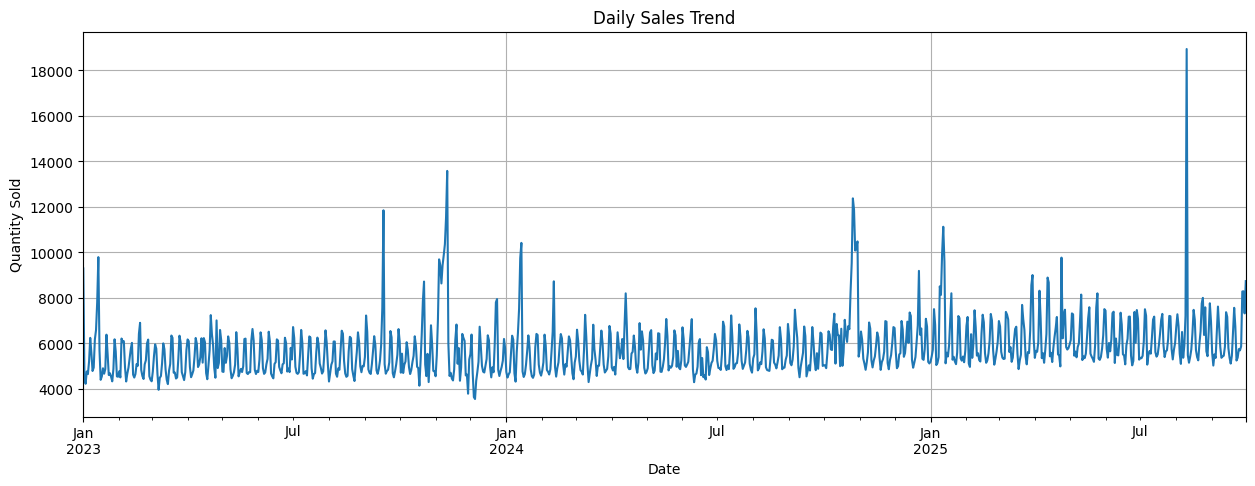

In [68]:
plt.figure(figsize=(15, 5))

daily_sales.plot()

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.grid(True)

plt.show()


In [69]:
sales["month"] = sales["date"].dt.month

monthly_sales = sales.groupby("month")["units_sold"].sum()

print(monthly_sales.head())

month
1    541578
2    471580
3    519934
4    525425
5    523313
Name: units_sold, dtype: int64


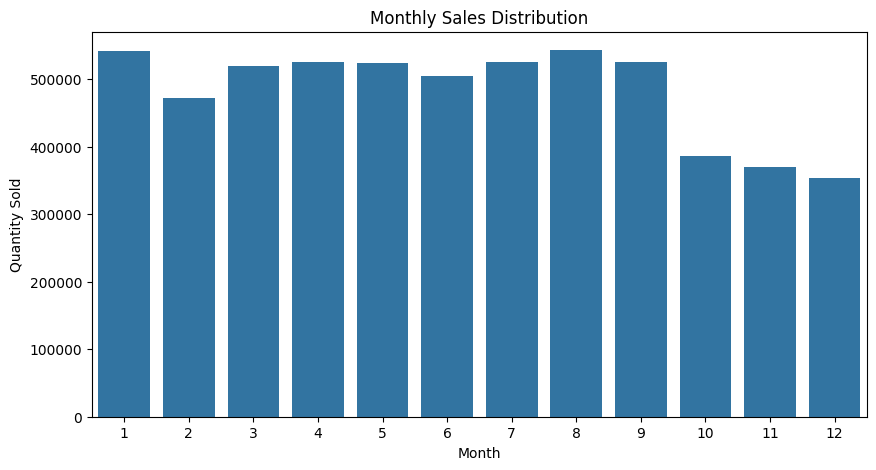

In [70]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales.values
)

plt.title("Monthly Sales Distribution")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")

plt.show()

year
2023    1991816
2024    2086438
2025    1710895
Name: units_sold, dtype: int64


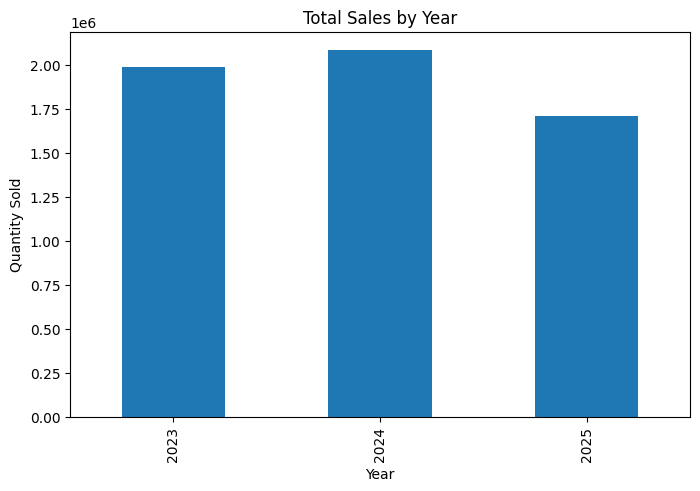

In [71]:
sales["year"] = sales["date"].dt.year

yearly_sales = sales.groupby("year")["units_sold"].sum()

print(yearly_sales)

yearly_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Quantity Sold")
plt.show()

In [72]:
sales["day_name"] = sales["date"].dt.day_name()

weekday_sales = sales.groupby("day_name")["units_sold"].mean()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

print(weekday_sales)

day_name
Monday       11.239183
Tuesday      10.870163
Wednesday    11.086373
Thursday     11.511878
Friday       12.612427
Saturday     15.001145
Sunday       14.655865
Name: units_sold, dtype: float64


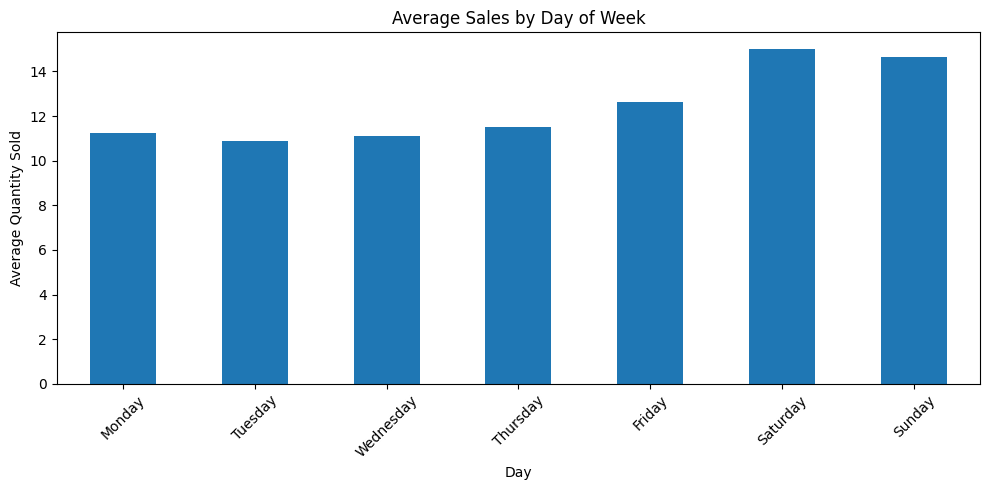

In [73]:
plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Quantity Sold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [74]:
store_sales = sales.groupby("store_id")["units_sold"].sum()

print(store_sales.sort_values(ascending=False))

store_id
S01    1369274
S03    1133733
S05     603555
S02     597555
S07     587801
S04     572921
S06     275180
S09     263592
S08     238038
S10     147500
Name: units_sold, dtype: int64


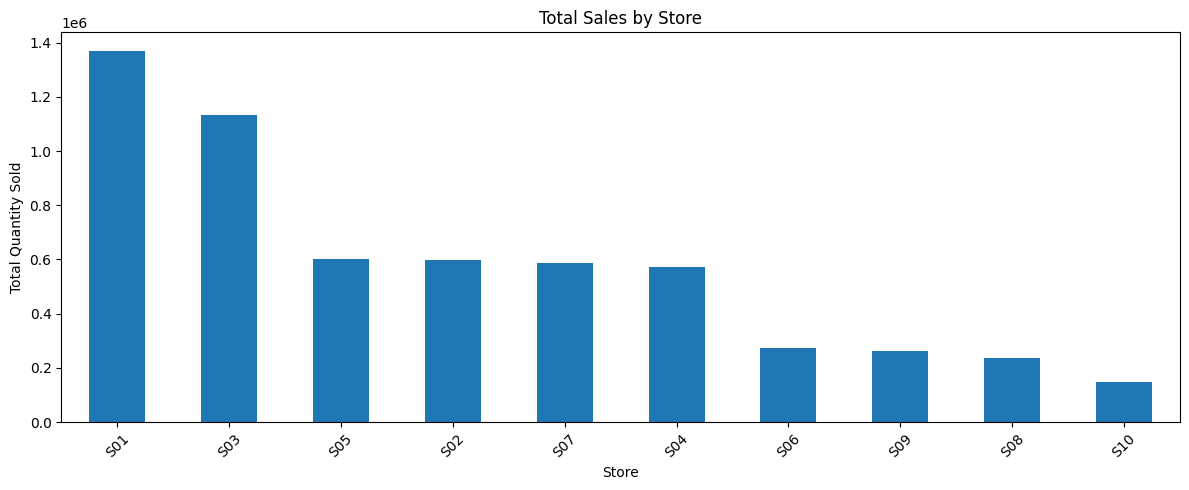

In [75]:
plt.figure(figsize=(12, 5))

store_sales.sort_values(ascending=False).plot(kind="bar")

plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Quantity Sold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [76]:
product_sales = sales.groupby("sku_id")["units_sold"].sum()

top_products = product_sales.sort_values(ascending=False).head(10)

print(top_products)

sku_id
P034    379345
P001    296362
P004    250768
P029    222510
P005    215571
P002    213422
P008    182673
P030    179605
P013    165663
P032    163372
Name: units_sold, dtype: int64


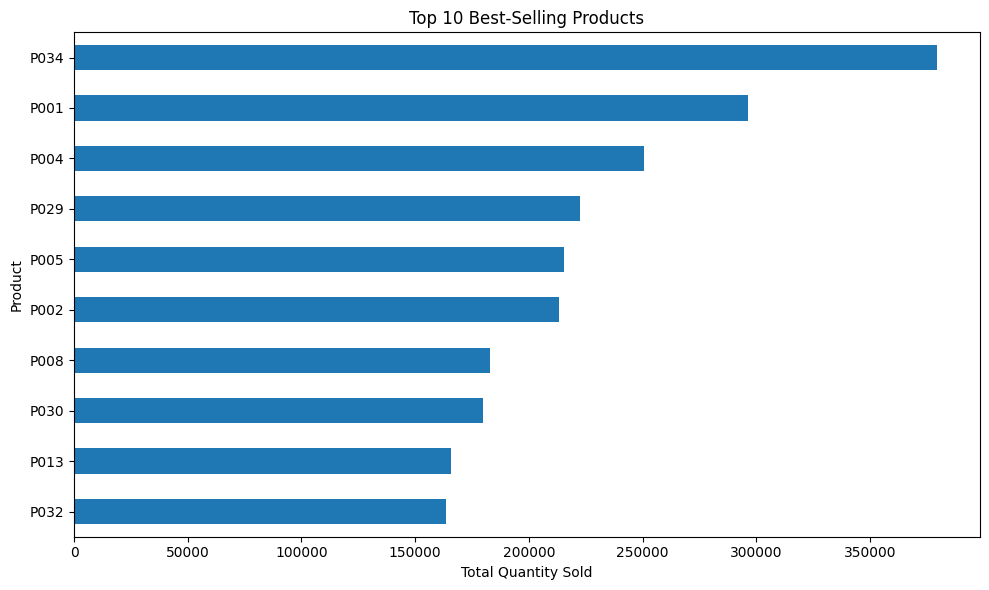

In [77]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

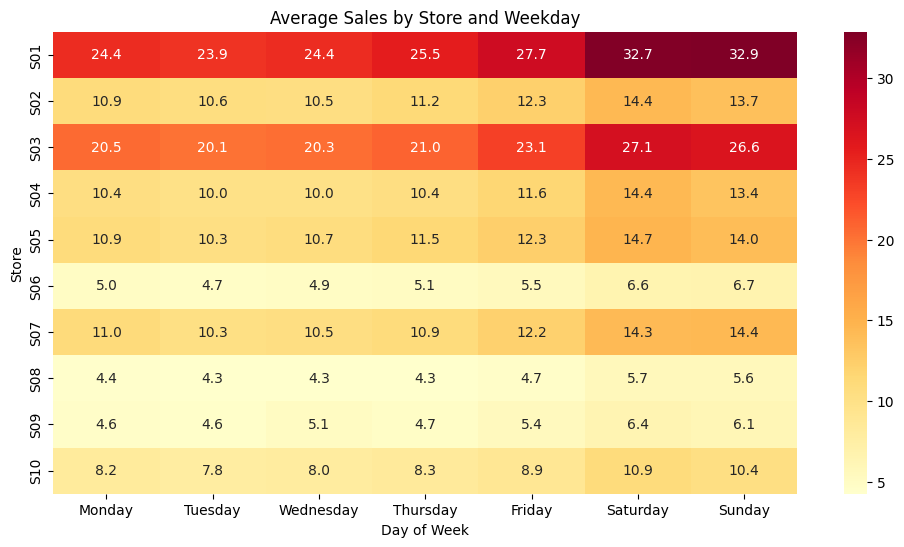

In [78]:
sales["day_name"] = sales["date"].dt.day_name()

store_weekday = sales.pivot_table(
    index="store_id",
    columns="day_name",
    values="units_sold",
    aggfunc="mean"
)

store_weekday = store_weekday.reindex(columns=weekday_order)

plt.figure(figsize=(12, 6))

sns.heatmap(
    store_weekday,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Average Sales by Store and Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Store")

plt.show()

In [79]:
sales["year"] = sales["date"].dt.year
sales["month"] = sales["date"].dt.month
sales["day"] = sales["date"].dt.day
sales["day_of_week"] = sales["date"].dt.dayofweek
sales["week"] = sales["date"].dt.isocalendar().week
sales["is_weekend"] = (sales["day_of_week"] >= 5).astype(int)

In [80]:
sales[[
    "date",
    "year",
    "month",
    "day",
    "day_of_week",
    "week",
    "is_weekend"
]].head()

,date,year,month,day,day_of_week,week,is_weekend
0,2023-01-01,2023,1,1,6,52,1
1,2023-01-02,2023,1,2,0,1,0
2,2023-01-03,2023,1,3,1,1,0
3,2023-01-04,2023,1,4,2,1,0
4,2023-01-05,2023,1,5,3,1,0


In [81]:
sales["units_sold"].describe()

,units_sold
count,465920.000000
mean,12.425200
std,28.560855
min,-111.000000
25%,3.000000
50%,7.000000
75%,15.000000
max,12000.000000


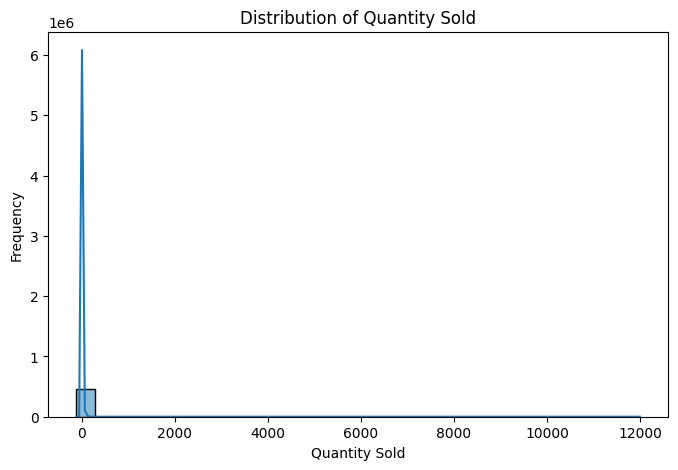

In [82]:
plt.figure(figsize=(8, 5))

sns.histplot(sales["units_sold"], bins=30, kde=True)

plt.title("Distribution of Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Frequency")

plt.show()

In [83]:
Q1 = sales["units_sold"].quantile(0.25)
Q3 = sales["units_sold"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = sales[
    (sales["units_sold"] < lower) |
    (sales["units_sold"] > upper)
]

print("Number of outliers:", len(outliers))
print("Upper limit:", upper)

Number of outliers: 35962
Upper limit: 33.0


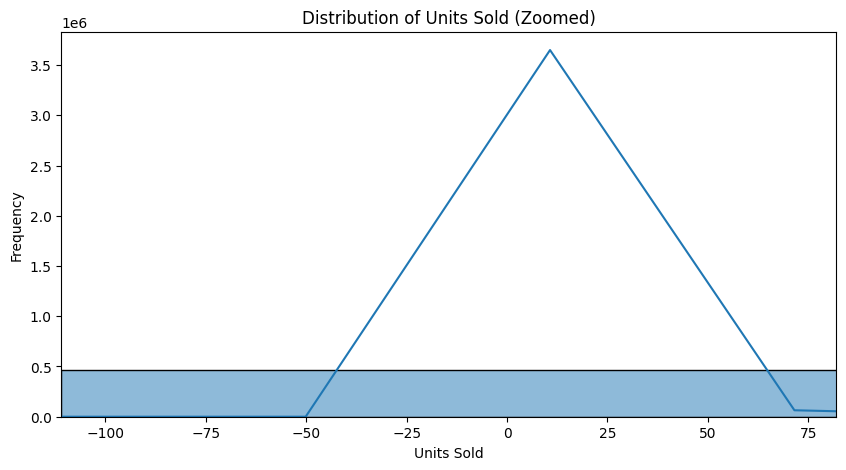

In [84]:
upper_limit = sales["units_sold"].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    sales["units_sold"],
    bins=50,
    kde=True
)

plt.xlim(
    sales["units_sold"].min(),
    upper_limit
)

plt.title("Distribution of Units Sold (Zoomed)")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")

plt.show()

In [85]:
sales["lag_1"] = sales.groupby(
    ["store_id", "sku_id"]
)["units_sold"].shift(1)

sales["lag_7"] = sales.groupby(
    ["store_id", "sku_id"]
)["units_sold"].shift(7)

sales["lag_14"] = sales.groupby(
    ["store_id", "sku_id"]
)["units_sold"].shift(14)

sales["lag_28"] = sales.groupby(
    ["store_id", "sku_id"]
)["units_sold"].shift(28)

In [86]:
sales["rolling_mean_7"] = sales.groupby(
    ["store_id", "sku_id"]
)["units_sold"].transform(
    lambda x: x.shift(1).rolling(7).mean()
)

sales["rolling_mean_28"] = sales.groupby(
    ["store_id", "sku_id"]
)["units_sold"].transform(
    lambda x: x.shift(1).rolling(28).mean()
)

In [87]:
stores = pd.read_csv("stores.csv")

print(stores.head())
print(stores.columns)

  store_id             city       format  area_sqft   opened_on
0      S01          Chennai  Hypermarket      42000  2016-04-10
1      S02          Chennai  Supermarket      18000  2018-08-15
2      S03       Coimbatore  Hypermarket      38000  2017-01-20
3      S04          Madurai  Supermarket      16000  2019-06-05
4      S05  Tiruchirappalli  Supermarket      15000  2019-11-12
Index(['store_id', 'city', 'format', 'area_sqft', 'opened_on'], dtype='object')


In [88]:
sales = sales.merge(
    stores[["store_id", "city"]],
    on="store_id",
    how="left"
)

In [89]:
weather = pd.read_csv("weather_daily.csv")

weather["date"] = pd.to_datetime(weather["date"])

In [90]:
sales = sales.merge(
    weather,
    on=["city", "date"],
    how="left"
)

In [91]:
festivals = pd.read_csv("festival_calendar_2023_2025.csv")

festivals["date"] = pd.to_datetime(festivals["date"])

In [92]:
sales = sales.merge(
    festivals[["date", "festival"]],
    on="date",
    how="left"
)

sales["is_festival"] = (
    sales["festival"].notna()
).astype(int)

In [93]:
print(sales.head())

print(sales.isnull().sum())

        date store_id sku_id  units_sold  selling_price  on_promo  \
0 2023-01-01      S01   P001         100           22.0         0   
1 2023-01-02      S01   P001          15           22.0         0   
2 2023-01-03      S01   P001          48           22.0         0   
3 2023-01-04      S01   P001          36           22.0         0   
4 2023-01-05      S01   P001          80           22.0         0   

   discount_pct  closing_stock  month  year  ... lag_7  lag_14  lag_28  \
0           0.0            NaN      1  2023  ...   NaN     NaN     NaN   
1           0.0            NaN      1  2023  ...   NaN     NaN     NaN   
2           0.0            NaN      1  2023  ...   NaN     NaN     NaN   
3           0.0            NaN      1  2023  ...   NaN     NaN     NaN   
4           0.0            NaN      1  2023  ...   NaN     NaN     NaN   

   rolling_mean_7  rolling_mean_28     city  rainfall_mm  max_temp_c  \
0             NaN              NaN  Chennai          0.0        25.1

In [94]:
sales.to_csv(
    "feature_store.csv",
    index=False
)

print("Feature store saved successfully!")

Feature store saved successfully!


In [47]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import numpy as np
import pandas as pd

sales = sales.sort_values(
    ["store_id", "sku_id", "date"]
)

forecast_results = []

for (store, sku), group in sales.groupby(
    ["store_id", "sku_id"]
):

    group = group.sort_values("date")

    if len(group) < 56:
        continue

    train = group.iloc[:-28]
    test = group.iloc[-28:]


    actual = test["units_sold"].values

    # 1. Seasonal Naive Forecast
    last_7_days = train["units_sold"].tail(7).values

    if len(last_7_days) < 7:
        continue

    seasonal_forecast = np.tile(last_7_days, 4)

    # 2. Moving Average Forecast
    moving_average = train["units_sold"].tail(28).mean()

    moving_average_forecast = np.repeat(
        moving_average, 28
    )

    # 3. ETS Forecast
    try:
        ets_model = ExponentialSmoothing(
            train["units_sold"].values,
            trend="add",
            seasonal="add",
            seasonal_periods=7,
            initialization_method="estimated"
        )

        ets_fitted = ets_model.fit()

        ets_forecast = ets_fitted.forecast(28)

    except Exception as e:
        print(f"ETS failed for {store}-{sku}: {e}")
        ets_forecast = np.repeat(np.nan, 28)

    # Store all forecasts
    for i in range(28):

        forecast_results.append({
            "store_id": store,
            "sku_id": sku,
            "date": test.iloc[i]["date"],
            "actual": actual[i],
            "seasonal_naive": seasonal_forecast[i],
            "moving_average": moving_average_forecast[i],
            "ets": ets_forecast[i]
        })

results = pd.DataFrame(forecast_results)

print(results.head(10))

  store_id sku_id       date  actual  seasonal_naive  moving_average  \
0      S01   P001 2025-08-23      73              26       51.392857   
1      S01   P001 2025-08-24      30              80       51.392857   
2      S01   P001 2025-08-27      97              24       51.392857   
3      S01   P001 2025-08-28      35              58       51.392857   
4      S01   P001 2025-08-30     165              44       51.392857   
5      S01   P001 2025-08-31      58              93       51.392857   
6      S01   P001 2025-09-01       8              41       51.392857   
7      S01   P001 2025-09-02      73              26       51.392857   
8      S01   P001 2025-09-03      34              80       51.392857   
9      S01   P001 2025-09-04      84              24       51.392857   

         ets  
0  47.611502  
1  55.526473  
2  60.510800  
3  47.958818  
4  52.183267  
5  47.733929  
6  45.080762  
7  47.563644  
8  55.478614  
9  60.462941  


In [48]:
def calculate_wape(actual, predicted):

    return (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
    ) * 100


# Seasonal Naive WAPE
seasonal_wape = calculate_wape(
    results["actual"],
    results["seasonal_naive"]
)

# Moving Average WAPE
moving_wape = calculate_wape(
    results["actual"],
    results["moving_average"]
)

# ETS WAPE
ets_wape = calculate_wape(
    results["actual"],
    results["ets"]
)


print("Seasonal Naive WAPE:", seasonal_wape)
print("Moving Average WAPE:", moving_wape)
print("ETS WAPE:", ets_wape)

Seasonal Naive WAPE: 88.62254223206868
Moving Average WAPE: 52.20128971001306
ETS WAPE: 65.91709234607453


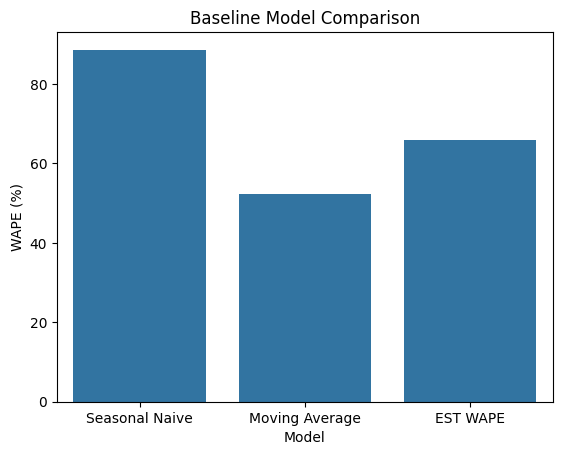

In [96]:
baseline_comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", "Moving Average","EST WAPE"],
    "WAPE": [seasonal_wape, moving_wape,ets_wape]
})

sns.barplot(
    data=baseline_comparison,
    x="Model",
    y="WAPE"
)

plt.title("Baseline Model Comparison")
plt.ylabel("WAPE (%)")
plt.show()